# Paper optimum against effective-parameter optimum

The paper's optimal syndrome interval depends on two constants besides `p`: the idling rate λ
and the readout multiplier `b_read`. The paper uses λ = 0.31 (its Willow fit) and `b_read = 1`.
Notebook 04 measured what one surface-code extraction round actually costs in Selene, which
gives **effective** values: λ = 0.10–0.15 and `b_read` = 1.35–1.50 (with `p_meas = 0.002`).

This notebook runs the paper's phenomenological model with each set and compares the optimal
interval Δt* from simulation (a Stim sweep at fixed total time `T = 96`) and from the paper's
Eq. 6. Same model, same decoder, same `p = 0.01`; only λ and `b_read` differ. Whether the full
Selene circuit agrees with this model is tested in 06 and 07.

**Result.**

| Δt* (sweep fit) | rot d=3 | d=5 | d=7 | unrot d=3 | d=5 | d=7 |
| --- | --- | --- | --- | --- | --- | --- |
| paper parameters | 6.42 | 2.72 | 1.59 | 5.48 | 2.18 | 1.23 |
| effective parameters | 16.57 | 8.03 | 4.43† | 15.96 | 6.76† | 2.84† |
| Eq. 6 ratio, `0.31/λ_eff` | 2.13 | 2.61 | 2.82 | 2.48 | 2.89 | 3.05 |
| λ alone, sweep ratio | 2.17 | 2.68 | 2.91 | 2.48 | 2.99 | 3.21 |

† optimum sits at a decoder weight tie (§8); decoder-sensitive.

- **The effective parameters lengthen the optimal interval 2.6–3.0×** (the three tie-free
  rows) and lower `p_L` at the optimum 1.6–2.5×.
- **λ does almost all of it, as Eq. 6 says.** Changing λ alone moves Δt* by 2.17–3.21×, within
  about 5% of Eq. 6's `0.31/λ_eff` on all six codes (largest gap 5.2%, unrotated d = 7).
- **`b_read` adds 7–16%**, which Eq. 6 has no term for.
- **Eq. 6's absolute Δt* is 17–31% short at `g = 0.8`** with the effective parameters; the
  sweep implies `g` = 0.68–0.75, in line with Stage 4a's 0.69–0.71 at d = 5–9.

## 0. Setup

**The model** is the paper's phenomenological memory (`docs/paper_equations.md`, Eqs. 1–3), run
in Stim with PyMatching on the exact detector error model:

```
p_idle = 1 − exp(−p·λ·Δt)
p_data = 1 − (1 − p)(1 − p_idle)          p_stab = p: extraction cost per round
p_read = b_read · p
```

Total time is fixed at `T = 96`, so `N = T/Δt` rounds, and minimising `p_L` is minimising the
paper's figure of merit `p_L/T`.

**Two parameter sets**, same `p = 0.01`, same model, same decoder:

| | λ | `b_read` |
| --- | --- | --- |
| **paper** | 0.31 (Willow fit) | 1 |
| **effective** | `1/n_data`, from 04 | `p_read/p` from 04's Z-ancilla cost plus `p_meas = 0.002` |

The effective set is what one surface-code extraction round costs in Selene, read from
`config/surface_extraction_measured.yaml` (written by `04_extraction_cost_surface`). To express
it at the same `p`: choose the per-op flip `f_1` so that one round costs the data exactly `p`,
then the Z-ancilla costs `p_anc = accumulate(n_anc, f_1)` and the recorded bit flips with
`p_read = 1 − (1 − p_meas)(1 − p_anc)`. `f_1` also gives the Selene `p_1q = 3·f_1/2` that this
operating point corresponds to.

**The optimum** is located the way Stage 4a located it: a parabola in `log Δt` fitted to
`log R`, with `R = −ln(1 − 2·p_L)/(2T)` (Eq. A3 inverted), over the points within a factor 2 of
the lowest one. The lowest sampled point alone is not used. When the points scatter more than
their error bars (χ²/dof > 1), the fit error is widened by `√(χ²/dof)`. The grid is `Δt = 96/N`
for every `N` from `d` to 24, plus `N` = 28, 32, 40, 48, 64, 96, 128, 192, so Δt runs from 0.5
to `96/d` and `N ≥ d` throughout.

**Shots:** 100,000 per seed, three seeds pooled per point (300,000). With a single seed, every
parameter set draws the same random numbers at a given `N`, so the same noise bump appears at
the same Δt in every curve and can masquerade as a shared effect.

**Eq. 6** is `qec_timing.ansatz.optimal_interval`, `Δt* = 1/(λ(α − 1))` with `α = g(d + 1)/2`,
at `g = 0.8` (the paper's fit, from d = 11–27) and `g = 0.70` (what Stage 4a measured at
d = 5–9). d = 3 is outside both ranges. Eq. 6 contains neither `p` nor `b_read`.

In [1]:
import pathlib, sys, time
import numpy as np
import pandas as pd
import stim, pymatching
import matplotlib.pyplot as plt
plt.rcParams['mathtext.fontset'] = 'cm'   # LaTeX-style math in figure labels
import yaml
from scipy.optimize import curve_fit

sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
from qec_timing.ansatz import optimal_interval     # Eq. 6, validated in Stage 4a

# ---- the knobs -------------------------------------------------------------
T = 96                              # fixed total time; R = T / tau rounds
P = 0.01                            # p: extraction cost per round, both parameter sets
P_MEAS = 0.002                      # readout flip in the effective set (06 and 07 use 0.002)
LAMBDA_PAPER, B_READ_PAPER = 0.31, 1.0
G_PAPER, G_STAGE4A = 0.8, 0.70      # Eq. 6: paper's fit (d=11-27), Stage 4a's (d=5-9)
SHOTS = 100_000                     # per seed
SEEDS = (1, 2, 3)                   # pooled per point; one seed alone gives
                                    # the same noise pattern to every parameter set
DISTANCES = (3, 5, 7)
R_EXTRA = (28, 32, 40, 48, 64, 96, 128, 192)   # R beyond 24: resolves tau from 0.5 to 4
P_L_SATURATED = 0.45                # points above this are left out of the fit
# ----------------------------------------------------------------------------

SPEC = {'rotated': 'surface_code:rotated_memory_z',
        'unrotated': 'surface_code:unrotated_memory_z'}
CODES = [(c, d) for c in SPEC for d in DISTANCES]
CONFIG = pathlib.Path.cwd().parent / "config"
MEASURED = yaml.safe_load((CONFIG / "surface_extraction_measured.yaml").read_text())["surface_measured"]
pd.set_option('display.width', 160)
BLUE, ORANGE, AQUA, INK, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e'


def accumulate(n, f):
    # P(odd number of flips) after n independent flips of probability f
    return (1 - (1 - 2 * f) ** n) / 2


def effective(code, d, p=P, p_meas=P_MEAS):
    # 04's measured charged-op counts, expressed at the same p as the paper set
    m = MEASURED[f"{code}_d{d}"]["ops_per_round"]
    n_data, n_anc = float(m["data_mean"]), float(m["ancilla_z"])
    f1 = (1 - (1 - 2 * p) ** (1 / n_data)) / 2      # per charged op: a round costs exactly p
    p_anc = accumulate(n_anc, f1)
    p_read = 1 - (1 - p_meas) * (1 - p_anc)
    return {'n_data': n_data, 'n_anc': n_anc, 'lam': 1 / n_data,
            'b_floor': n_anc / n_data, 'b_read': p_read / p, 'p_1q': 1.5 * f1}


EFF = {k: effective(*k) for k in CODES}
eff_tab = pd.DataFrame([{'code': c, 'd': d, 'n_data': round(e['n_data'], 3),
                         'n_anc': round(e['n_anc'], 3), 'lambda': round(e['lam'], 4),
                         'b_read floor': round(e['b_floor'], 3),
                         f'b_read (p_meas={P_MEAS})': round(e['b_read'], 3),
                         'Selene p_1q at p=0.01': round(e['p_1q'], 5)}
                        for (c, d), e in EFF.items()]).set_index(['code', 'd'])
print(f"effective parameters from config/surface_extraction_measured.yaml, at p = {P}\n")
print(eff_tab.to_string())


def memory(d, rounds, p_data, p_read, spec):
    # Phenomenological memory: X on each data qubit once per round, a flip on each recorded
    # bit. Only the data channel and the measurement flip are on, and DEPOLARIZE1 -> X_ERROR
    # makes the data channel bit-flip. Extraction is noiseless, so nothing propagates.
    c = stim.Circuit.generated(
        spec, distance=d, rounds=rounds,
        before_round_data_depolarization=float(np.clip(p_data, 0, 0.5)),
        before_measure_flip_probability=float(np.clip(p_read, 0, 0.5)))
    text = str(c)
    assert 'DEPOLARIZE2' not in text, "a two-qubit channel is live; it should not be"
    return stim.Circuit(text.replace('DEPOLARIZE1(', 'X_ERROR('))


def logical_error(circ, shots=SHOTS, seeds=SEEDS):
    # pooled over seeds: `shots` per seed
    m = pymatching.Matching.from_detector_error_model(
        circ.detector_error_model(decompose_errors=True))
    fails = 0
    for seed in seeds:
        dets, obs = circ.compile_detector_sampler(seed=seed).sample(
            shots, separate_observables=True)
        fails += int(np.sum(m.decode_batch(dets)[:, 0] != obs[:, 0]))
    n = shots * len(seeds)
    e = fails / n
    return e, float(np.sqrt(max(e * (1 - e), 1e-12) / n))


print('\nnoiseless ->', logical_error(memory(3, 3, 0.0, 0.0, SPEC['rotated']), shots=5000, seeds=(1,))[0])

effective parameters from config/surface_extraction_measured.yaml, at p = 0.01

             n_data   n_anc  lambda  b_read floor  b_read (p_meas=0.002)  Selene p_1q at p=0.01
code      d                                                                                    
rotated   3   6.889   8.967  0.1452         1.302                  1.495                0.00220
          5   8.398   9.889  0.1191         1.178                  1.373                0.00180
          7   9.114  10.726  0.1097         1.177                  1.372                0.00166
unrotated 3   7.991  10.464  0.1251         1.309                  1.503                0.00189
          5   9.300  11.082  0.1075         1.192                  1.387                0.00163
          7   9.878  11.363  0.1012         1.150                  1.346                0.00153

noiseless -> 0.0


## 1. Check: is the data channel bit-flip at rate `p`?

A depolarizing channel at `q` flips a qubit in Z with probability `2q/3`, so `X_ERROR(p)` and
`DEPOLARIZE1(3p/2)` must give the same logical error rate if the rewrite in `memory` did
what it should. d = 5, 5 rounds, no readout noise, four values of `p`.

In [2]:
rows = []
for p in (0.004, 0.008, 0.012, 0.016):
    bit = logical_error(memory(5, 5, p, 0.0, SPEC['rotated']))
    dep = logical_error(stim.Circuit.generated(
        SPEC['rotated'], distance=5, rounds=5,
        before_round_data_depolarization=1.5 * p,
        before_measure_flip_probability=0.0))
    s = np.hypot(bit[1], dep[1])
    rows.append({'p': p, 'X_ERROR(p)': round(bit[0], 5), 'DEPOLARIZE1(3p/2)': round(dep[0], 5),
                 'sigma': round(s, 5), 'diff / sigma': round((bit[0] - dep[0]) / s, 2)})
chk = pd.DataFrame(rows).set_index('p')
print("d=5, 5 rounds, no readout noise\n")
print(chk.to_string())
print(f"\nlargest |diff| = {chk['diff / sigma'].abs().max():.2f} sigma")

d=5, 5 rounds, no readout noise

       X_ERROR(p)  DEPOLARIZE1(3p/2)    sigma  diff / sigma
p                                                          
0.004     0.00008            0.00010  0.00002         -0.54
0.008     0.00074            0.00066  0.00007          1.12
0.012     0.00224            0.00218  0.00012          0.50
0.016     0.00549            0.00527  0.00019          1.15

largest |diff| = 1.15 sigma


## 2. The sweep and the optimum estimate

`sweep` runs one parameter set over the Δt grid; `fit_optimum` locates Δt* by the parabola fit
described in §0 and also reports the lowest sampled point, and how far it sits below each end
of the grid in σ. An optimum is called **interior** only if the lowest point is not an end of
the grid and the parabola is convex.

In [3]:
def rounds_grid(d):
    return sorted(set(range(d, 25)) | set(R_EXTRA), reverse=True)   # ascending tau


def sweep(code, d, lam, b_read, p=P, p_stab_on=True, shots=SHOTS, seeds=SEEDS, rounds=None):
    rows = []
    for R in (rounds or rounds_grid(d)):
        tau = T / R
        p_idle = 1 - np.exp(-p * lam * tau)
        p_data = 1 - (1 - p) * (1 - p_idle) if p_stab_on else p_idle
        e, s = logical_error(memory(d, R, p_data, b_read * p, SPEC[code]), shots, seeds)
        rows.append({'tau': tau, 'R': R, 'pL': e, 'sigma': s})
    return pd.DataFrame(rows).sort_values('tau').reset_index(drop=True)


def rate(pL, s):
    # Eq. A3 inverted: p_L = (1 - exp(-2 R T))/2  ->  R, and the error on log R
    R = -np.log1p(-2 * pL) / (2 * T)
    return R, s / ((1 - 2 * pL) * T * R)


def fit_optimum(df, window=2.0):
    ok = df[(df.pL > 0) & (df.pL < P_L_SATURATED)]
    i = ok.pL.idxmin()
    t0 = float(ok.loc[i, 'tau'])
    lo = (df.pL.iloc[0] - ok.loc[i, 'pL']) / np.hypot(df.sigma.iloc[0], ok.loc[i, 'sigma'])
    hi = (df.pL.iloc[-1] - ok.loc[i, 'pL']) / np.hypot(df.sigma.iloc[-1], ok.loc[i, 'sigma'])
    out = {'tau* (lowest point)': round(t0, 2), 'pL at min': round(float(ok.loc[i, 'pL']), 5),
           'sigma vs smallest tau': round(float(lo), 1),
           'sigma vs largest tau': round(float(hi), 1),
           'tau* (fit)': np.nan, 'fit +/-': np.nan, 'chi2/dof': np.nan, 'interior': 'no'}
    if t0 in (df.tau.min(), df.tau.max()):
        return out
    w = ok[(ok.tau >= t0 / window) & (ok.tau <= t0 * window)]
    if len(w) < 4:
        return out
    R, sR = rate(w.pL.values, w.sigma.values)
    u = np.log(w.tau.values)
    (a, b, c), cov = curve_fit(lambda u, a, b, c: a + b * u + c * u * u, u, np.log(R),
                               sigma=sR, absolute_sigma=True)
    if c <= 0:
        return out
    chi2 = float(np.sum(((np.log(R) - (a + b * u + c * u * u)) / sR) ** 2) / (len(u) - 3))
    cov = cov * max(chi2, 1.0)          # scatter beyond the error bars widens the error
    grad = np.array([0.0, -1 / (2 * c), b / (2 * c * c)])
    ts = float(np.exp(-b / (2 * c)))
    out.update({'tau* (fit)': round(ts, 2),
                'fit +/-': round(ts * float(np.sqrt(max(grad @ cov @ grad, 0))), 2),
                'chi2/dof': round(chi2, 2), 'interior': 'yes'})
    return out


def tau_tie(lam, b_read, p=P):
    # tau at which p_data(tau) = p_read: data and readout edges get equal decoder weight
    if b_read <= 1:
        return np.nan                       # p_data > p_read for every tau > 0
    return float(np.log((1 - p) / (1 - b_read * p)) / (p * lam))


def eq6(d, lam):
    return {'Eq.6 g=0.8': round(optimal_interval(d=d, lam=lam, g=G_PAPER), 2),
            'Eq.6 g=0.70': round(optimal_interval(d=d, lam=lam, g=G_STAGE4A), 2)}


def run_set(label, params, shots=SHOTS, seeds=SEEDS):
    # params(code, d) -> (lam, b_read); returns (curves, table)
    curves, rows, t0 = {}, [], time.time()
    for c, d in CODES:
        lam, br = params(c, d)
        curves[(c, d)] = sweep(c, d, lam, br, shots=shots, seeds=seeds)
        fit, tt = fit_optimum(curves[(c, d)]), tau_tie(lam, br)
        t_low = fit['tau* (lowest point)']
        rows.append({'code': c, 'd': d, 'lambda': round(lam, 4), 'b_read': round(br, 3),
                     **fit, **eq6(d, lam), 'tau tie': round(tt, 2),
                     'tie in fit window': 'yes' if t_low / 2 <= tt <= t_low * 2 else 'no'})
    tab = pd.DataFrame(rows).set_index(['code', 'd'])
    print(f"{label}: T={T}, p={P}, {shots * len(seeds)} shots per point "
          f"({len(seeds)} seeds) [{time.time() - t0:.0f}s]\n")
    return curves, tab


print("tau grid, d=3:", [round(t, 2) for t in sorted(T / R for R in rounds_grid(3))])
print("tau grid, d=7:", [round(t, 2) for t in sorted(T / R for R in rounds_grid(7))])

tau grid, d=3: [0.5, 0.75, 1.0, 1.5, 2.0, 2.4, 3.0, 3.43, 4.0, 4.17, 4.36, 4.57, 4.8, 5.05, 5.33, 5.65, 6.0, 6.4, 6.86, 7.38, 8.0, 8.73, 9.6, 10.67, 12.0, 13.71, 16.0, 19.2, 24.0, 32.0]
tau grid, d=7: [0.5, 0.75, 1.0, 1.5, 2.0, 2.4, 3.0, 3.43, 4.0, 4.17, 4.36, 4.57, 4.8, 5.05, 5.33, 5.65, 6.0, 6.4, 6.86, 7.38, 8.0, 8.73, 9.6, 10.67, 12.0, 13.71]


## 3. At the paper's parameters

λ = 0.31, `b_read = 1`, for all six codes. `tau tie` is empty: at `b_read = 1` the data and
readout rates never meet.

In [4]:
paper_curves, paper = run_set("paper parameters",
                              lambda c, d: (LAMBDA_PAPER, B_READ_PAPER))
print(paper.to_string())

paper parameters: T=96, p=0.01, 300000 shots per point (3 seeds) [937s]

             lambda  b_read  tau* (lowest point)  pL at min  sigma vs smallest tau  sigma vs largest tau  tau* (fit)  fit +/-  chi2/dof interior  Eq.6 g=0.8  Eq.6 g=0.70  tau tie tie in fit window
code      d                                                                                                                                                                                         
rotated   3    0.31     1.0                 6.86    0.23203                  166.3                  64.4        6.42     0.05      0.84      yes        5.38         8.06      NaN                no
          5    0.31     1.0                 3.00    0.13303                   96.0                 124.2        2.72     0.02      0.81      yes        2.30         2.93      NaN                no
          7    0.31     1.0                 1.50    0.05720                   36.2                 164.6        1.59     0.02      0.18    

## 4. Control: switch `p_stab` off

The same paper-parameter sweep with the constant extraction term removed, so the data fault is
`p_idle` alone (100,000 shots, one seed: only the position of the lowest point matters).

Without `p_stab`, the total idle error over the fixed `T` is about `p·λ·T` whatever Δt is. What
changes with Δt is how it is dosed: many small doses (short Δt, many rounds) or a few large ones.
The code corrects up to `(d − 1)/2` faults between consecutive syndrome rounds, so small doses
are corrected far more reliably. Readout faults grow with the number of rounds and push the
other way. If `p_stab` is what creates the optimum, `p_L` should fall all the way to the
shortest Δt on the grid.

In [5]:
rows = []
for c, d in CODES:
    df = sweep(c, d, LAMBDA_PAPER, B_READ_PAPER, p_stab_on=False, seeds=(1,))
    i = df.pL.idxmin()
    rows.append({'code': c, 'd': d,
                 'tau* with p_stab (fit)': paper.loc[(c, d), 'tau* (fit)'],
                 'lowest point without p_stab': round(float(df.loc[i, 'tau']), 2),
                 'pL at smallest tau': round(float(df.pL.iloc[0]), 5),
                 'pL at largest tau': round(float(df.pL.iloc[-1]), 5)})
ctrl = pd.DataFrame(rows).set_index(['code', 'd'])
print(f"paper parameters, p_stab off, everything else identical; {SHOTS} shots, one seed\n")
print(ctrl.to_string())

paper parameters, p_stab off, everything else identical; 100000 shots, one seed

             tau* with p_stab (fit)  lowest point without p_stab  pL at smallest tau  pL at largest tau
code      d                                                                                            
rotated   3                    6.42                         0.50             0.02702            0.27624
          5                    2.72                         0.50             0.00154            0.20540
          7                    1.59                         0.50             0.00013            0.11870
unrotated 3                    5.48                         0.50             0.02383            0.32928
          5                    2.18                         0.50             0.00080            0.21493
          7                    1.23                         0.75             0.00005            0.10321


## 5. At the effective parameters

λ = `1/n_data` and `b_read = p_read/p` from §0, each code with its own values.

In [6]:
eff_curves, eff = run_set("effective parameters",
                          lambda c, d: (EFF[(c, d)]['lam'], EFF[(c, d)]['b_read']))
print(eff.to_string())

effective parameters: T=96, p=0.01, 300000 shots per point (3 seeds) [921s]

             lambda  b_read  tau* (lowest point)  pL at min  sigma vs smallest tau  sigma vs largest tau  tau* (fit)  fit +/-  chi2/dof interior  Eq.6 g=0.8  Eq.6 g=0.70  tau tie tie in fit window
code      d                                                                                                                                                                                         
rotated   3  0.1452   1.495                19.20    0.14211                  266.2                   8.7       16.57     0.38      1.78      yes       11.48        17.22     3.45                no
          5  0.1191   1.373                 8.73    0.06544                  172.7                  19.6        8.03     0.07      0.86      yes        6.00         7.63     3.17                no
          7  0.1097   1.372                 4.17    0.02618                   83.8                  21.8        4.43     0.13      1.61

## 6. Paper optimum against effective optimum

One row per code: Δt* from the sweep fit and from Eq. 6, for each parameter set, and the ratio
effective / paper. Eq. 6's ratio is exactly `0.31/λ_eff`, since neither `g` nor `b_read`
enters it.

The last column flags effective-parameter rows whose fit window contains the decoder weight
tie (§8); their sweep Δt* is decoder-sensitive.

In [7]:
cmp = pd.DataFrame({
    'paper: fit': paper['tau* (fit)'], 'paper: +/-': paper['fit +/-'],
    'paper: Eq.6 (0.8 / 0.70)': [f"{a} / {b}" for a, b in zip(paper['Eq.6 g=0.8'], paper['Eq.6 g=0.70'])],
    'effective: fit': eff['tau* (fit)'], 'effective: +/-': eff['fit +/-'],
    'effective: Eq.6 (0.8 / 0.70)': [f"{a} / {b}" for a, b in zip(eff['Eq.6 g=0.8'], eff['Eq.6 g=0.70'])],
    'ratio: fit': (eff['tau* (fit)'] / paper['tau* (fit)']).round(2),
    'ratio: Eq.6': (eff['Eq.6 g=0.8'] / paper['Eq.6 g=0.8']).round(2),
    'effective: tie in window': eff['tie in fit window'],
})
print(cmp.to_string())

# where each fit sits relative to Eq. 6: the g at which Eq. 6 reproduces the fitted tau*
def g_implied(d, lam, tau):
    return float(2 * (1 + 1 / (lam * tau)) / (d + 1))   # alpha - 1 = 1/(lam tau)

gi = pd.DataFrame({
    'g implied, paper': [round(g_implied(d, LAMBDA_PAPER, t), 3) if np.isfinite(t) else np.nan
                         for (c, d), t in zip(CODES, paper['tau* (fit)'])],
    'g implied, effective': [round(g_implied(d, EFF[(c, d)]['lam'], t), 3) if np.isfinite(t) else np.nan
                             for (c, d), t in zip(CODES, eff['tau* (fit)'])],
}, index=paper.index)
print("\ng at which Eq. 6 reproduces each fitted tau*\n")
print(gi.to_string())

             paper: fit  paper: +/- paper: Eq.6 (0.8 / 0.70)  effective: fit  effective: +/- effective: Eq.6 (0.8 / 0.70)  ratio: fit  ratio: Eq.6 effective: tie in window
code      d                                                                                                                                                                
rotated   3        6.42        0.05              5.38 / 8.06           16.57            0.38                11.48 / 17.22        2.58         2.13                       no
          5        2.72        0.02               2.3 / 2.93            8.03            0.07                   6.0 / 7.63        2.95         2.61                       no
          7        1.59        0.02              1.47 / 1.79            4.43            0.13                  4.14 / 5.06        2.79         2.82                      yes
unrotated 3        5.48        0.05              5.38 / 8.06           15.96            0.25                13.32 / 19.98        2.91       

## 7. Which constant moves Δt*?

Eq. 6 attributes the whole shift to λ. The sweep can separate the two constants: change one at
a time from the paper set, with everything else fixed.
The last column flags fits whose window contains the decoder weight tie (§8).

In [8]:
lam_only_curves, lam_only = run_set("effective lambda, paper b_read = 1",
                                    lambda c, d: (EFF[(c, d)]['lam'], B_READ_PAPER))
bread_only_curves, bread_only = run_set("paper lambda = 0.31, effective b_read",
                                        lambda c, d: (LAMBDA_PAPER, EFF[(c, d)]['b_read']))
split = pd.DataFrame({
    'paper': paper['tau* (fit)'],
    'lambda only': lam_only['tau* (fit)'],
    'b_read only': bread_only['tau* (fit)'],
    'both (effective)': eff['tau* (fit)'],
})
split['lambda only / paper'] = (split['lambda only'] / split['paper']).round(2)
split['b_read only / paper'] = (split['b_read only'] / split['paper']).round(2)
split['both / paper'] = (split['both (effective)'] / split['paper']).round(2)
print("tau* (fit) as the constants are changed one at a time\n")
split['tie in window (b_read only / both)'] = [f"{a} / {b}" for a, b in zip(bread_only['tie in fit window'], eff['tie in fit window'])]
print(split.to_string())

effective lambda, paper b_read = 1: T=96, p=0.01, 300000 shots per point (3 seeds) [850s]



paper lambda = 0.31, effective b_read: T=96, p=0.01, 300000 shots per point (3 seeds) [1058s]

tau* (fit) as the constants are changed one at a time

             paper  lambda only  b_read only  both (effective)  lambda only / paper  b_read only / paper  both / paper tie in window (b_read only / both)
code      d                                                                                                                                              
rotated   3   6.42        13.94         7.27             16.57                 2.17                 1.13          2.58                            no / no
          5   2.72         7.29         2.90              8.03                 2.68                 1.07          2.95                            no / no
          7   1.59         4.62         1.37              4.43                 2.91                 0.86          2.79                          yes / yes
unrotated 3   5.48        13.57         6.37             15.96                 2

## 8. A decoder effect where the two error rates meet

When `b_read > 1`, the data fault rate `p_data(Δt)` grows through the readout rate `p_read` at

```
Δt_tie = ln((1 − p)/(1 − b_read·p)) / (p·λ)
```

and there the decoder's data edges and measurement edges have **equal weight**. With every
data edge alike and every measurement edge alike, minimum-weight matching flips many decisions
at once as the weight ratio passes 1, so `p_L` steps rather than changing smoothly. At
`b_read = 1` there is no crossing (`p_data > p_read` for every Δt > 0), so the paper-parameter and
λ-only curves are smooth.

The test holds the samples fixed and changes only the decoder: unrotated d = 7 at the effective
parameters, where `Δt_tie` = 3.4 lies between the grid points Δt = 3.43 (N = 28) and 4.0 (N = 24).
Each circuit is sampled once (three seeds, 300,000 shots), then decoded with the measurement
weight set to `p_read' = ratio · p_data`, for ratios either side of 1.

In [9]:
c, d = 'unrotated', 7
lam, br = EFF[(c, d)]['lam'], EFF[(c, d)]['b_read']
print(f"{c} d={d}, effective: lambda={lam:.4f}, b_read={br:.3f}, tau_tie={tau_tie(lam, br):.2f}\n")
rows = []
for R in (28, 24):
    tau = T / R
    p_data = 1 - (1 - P) * np.exp(-P * lam * tau)
    truth = memory(d, R, p_data, br * P, SPEC[c])
    samples = [truth.compile_detector_sampler(seed=s).sample(SHOTS, separate_observables=True)
               for s in SEEDS]
    dets = np.vstack([s[0] for s in samples]); obs = np.vstack([s[1] for s in samples])[:, 0]

    def decode(circ):
        m = pymatching.Matching.from_detector_error_model(circ.detector_error_model(decompose_errors=True))
        return float(np.mean(m.decode_batch(dets)[:, 0] != obs))

    row = {'R': R, 'tau': round(tau, 2), 'true p_read / p_data': round(br * P / p_data, 4)}
    for ratio in (0.97, 0.99, 1.01, 1.03):
        row[f'decoder ratio {ratio}'] = round(decode(memory(d, R, p_data, ratio * p_data, SPEC[c])), 5)
    row['true weights'] = round(decode(truth), 5)
    rows.append(row)
tie = pd.DataFrame(rows).set_index('R')
print(tie.to_string())
print(f"\nsigma per entry ~ {np.sqrt(0.011 * 0.989 / (SHOTS * len(SEEDS))):.5f}; entries in a row share "
      "the same samples, so their differences are decoder differences only.")

unrotated d=7, effective: lambda=0.1012, b_read=1.346, tau_tie=3.46



     tau  true p_read / p_data  decoder ratio 0.97  decoder ratio 0.99  decoder ratio 1.01  decoder ratio 1.03  true weights
R                                                                                                                           
28  3.43                1.0024             0.01170             0.01170             0.01028             0.01028       0.01028
24  4.00                0.9616             0.01176             0.01176             0.01023             0.01023       0.01176

sigma per entry ~ 0.00019; entries in a row share the same samples, so their differences are decoder differences only.


## 9. Figures

Left figure: `p_L` against Δt for both parameter sets, rotated and unrotated; ringed points are
the lowest sampled points.

Right figure: Δt* against d. Points are the sweep fits with their error bars; the bands span
Eq. 6 from `g = 0.70` to `g = 0.8`.

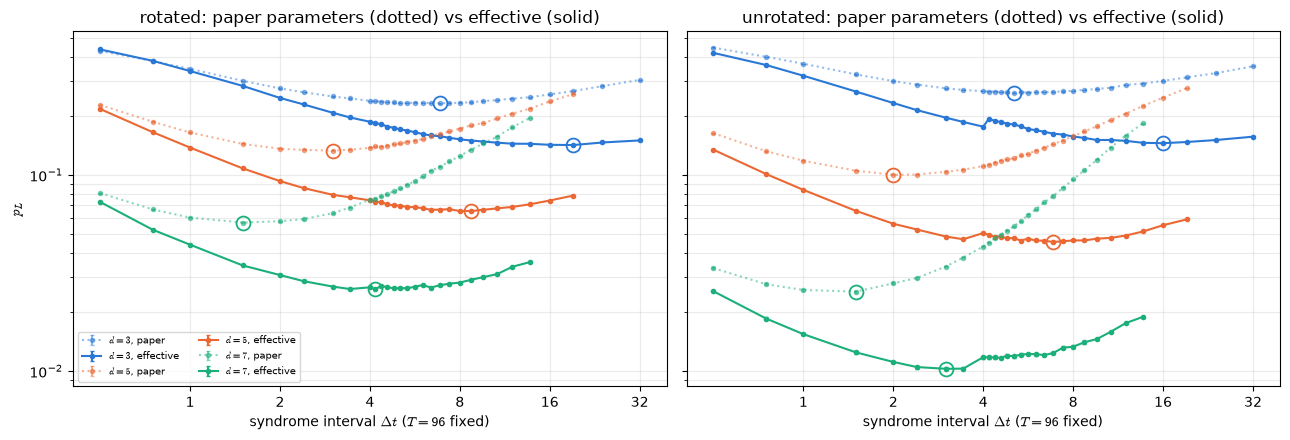

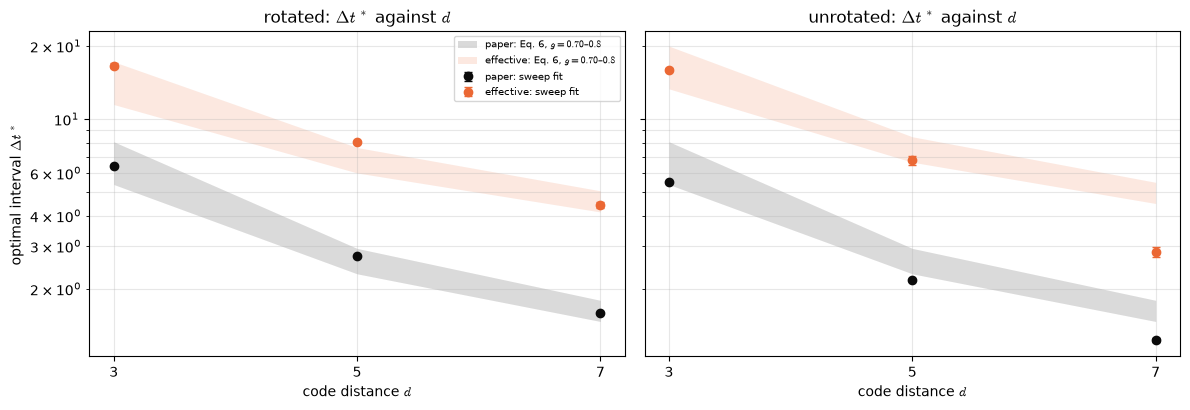

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, name in zip(axes, SPEC):
    for d, col in zip(DISTANCES, (BLUE, ORANGE, AQUA)):
        for tag, store, ls in (('paper', paper_curves, ':'), ('effective', eff_curves, '-')):
            df = store[(name, d)]
            ax.errorbar(df.tau, df.pL, yerr=df.sigma, marker='o', ms=3, capsize=1.5,
                        color=col, ls=ls, alpha=1.0 if ls == '-' else .5, label=f'$d={d}$, {tag}')
            i = df.pL.idxmin()
            ax.plot([df.tau[i]], [df.pL[i]], marker='o', ms=10, mfc='none', mec=col, mew=1.3)
    ax.set_xscale('log', base=2); ax.set_yscale('log')
    ax.set_xticks([1, 2, 4, 8, 16, 32])
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.set_xlabel(r'syndrome interval $\Delta t$ ($T = 96$ fixed)')
    ax.set_title(f'{name}: paper parameters (dotted) vs effective (solid)')
    ax.grid(alpha=.25, which='both')
axes[0].set_ylabel(r'$p_L$')
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig('figures/05a_pL_vs_tau.png', bbox_inches='tight', facecolor='white')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
ds = np.array(DISTANCES)
for ax, name in zip(axes, SPEC):
    for tag, tab, lamf, col in (('paper', paper, lambda d: LAMBDA_PAPER, INK),
                                ('effective', eff, lambda d: EFF[(name, d)]['lam'], ORANGE)):
        lo = [optimal_interval(d=d, lam=lamf(d), g=G_PAPER) for d in ds]
        hi = [optimal_interval(d=d, lam=lamf(d), g=G_STAGE4A) for d in ds]
        ax.fill_between(ds, lo, hi, color=col, alpha=.15, lw=0,
                        label=f'{tag}: Eq. 6, $g = 0.70$–$0.8$')
        sub = tab.loc[name]
        ax.errorbar(ds, sub['tau* (fit)'], yerr=sub['fit +/-'], marker='o', ms=6, capsize=3,
                    color=col, ls='none', label=f'{tag}: sweep fit')
    ax.set_yscale('log'); ax.set_xticks(ds); ax.set_xlabel(r'code distance $d$')
    ax.set_title(f'{name}: $\\Delta t^*$ against $d$'); ax.grid(alpha=.3, which='both')
axes[0].set_ylabel(r'optimal interval $\Delta t^*$'); axes[0].legend(fontsize=7)
plt.tight_layout()
plt.savefig('figures/05b_tau_star_vs_d.png', bbox_inches='tight', facecolor='white')
plt.show()

## 10. Findings

**1. The effective parameters lengthen the optimal interval 2.6–3.0× and roughly halve `p_L`
there.** On the three rows free of the decoder tie, Δt* goes from 6.42 to 16.57 (rotated d = 3),
2.72 to 8.03 (rotated d = 5) and 5.48 to 15.96 (unrotated d = 3). `p_L` at the optimum falls by
1.6–2.5× across all six codes (e.g. 0.133 → 0.065 at rotated d = 5), because idling is 2–3×
cheaper relative to a round.

**2. λ accounts for nearly all of the shift, as Eq. 6 predicts.** With `b_read` held at 1,
changing λ alone moves Δt* by 2.17, 2.68, 2.91 (rotated) and 2.48, 2.99, 3.21 (unrotated), against
Eq. 6's `0.31/λ_eff` of 2.13, 2.61, 2.82 and 2.48, 2.89, 3.05: within 0–5.2% on every code. The
λ-only curves have no weight tie, so this holds at d = 7 too.

**3. `b_read` lengthens Δt* by 7–16%, and Eq. 6 has no term for it.** Raising `b_read` alone
from 1 to its effective value moves Δt* by 1.13× (rotated d = 3), 1.07× (rotated d = 5) and 1.16×
(unrotated d = 3). More readout error per round makes each round costlier, so fewer rounds
pay. Combined with λ the effects multiply approximately (2.17 × 1.13 = 2.45 against 2.58
measured at rotated d = 3).

**4. Eq. 6 at `g = 0.8` sits short of the sweep, by more for the effective set.** At paper
parameters the sweep Δt* lies inside the Eq. 6 band (`g` = 0.70–0.8) for rotated d = 3, 5, 7 and
unrotated d = 3 (implied `g` 0.73–0.79), and below it for unrotated d = 5 and 7 (`g` 0.83 and
0.91). At effective parameters Eq. 6 with `g = 0.8` is 17–31% short on the tie-free rows
(implied `g` 0.68–0.75), consistent with Stage 4a's small-d value of 0.69–0.71. Part of the gap
is finding 3: Eq. 6 omits `b_read`, and a `g` fitted to it absorbs `b_read`'s lengthening.

**5. Where `p_data` crosses `p_read`, the decoder makes `p_L` step, and at d = 7 the optimum
sits there.** With `b_read > 1`, `p_data(Δt) = p_read` at Δt_tie = 3.2–4.1 (effective set) and
1.1–1.6 (`b_read` alone). On identical samples at unrotated d = 7, Δt = 4.0, the true-weight
decoder gives `p_L` = 0.01176. Decoding the same samples as if `p_read` were 1% above `p_data`
(the truth is 4% below) gives 0.01023: 15% from a decoder choice alone (§8). At Δt = 3.43, just before the tie, the true weights
already land on the better side (0.01028). This steps the curve up just after Δt_tie and pulls
the fitted optimum below it wherever the optimum is close. That is why the effective Δt* at
unrotated d = 7 (2.84) comes out *below* the λ-only Δt* (3.95), which finding 3 rules out
physically, and why the `b_read`-only fits at d = 7 move Δt* *down* (×0.86, ×0.77). These rows
(marked †) measure the decoder at the tie, not the noise. MWPM with the true weights is not the
best decoder there.

**6. The control holds: without `p_stab` there is no interior optimum.** `p_L` falls towards
the shortest interval, with the lowest point at Δt = 0.5 (the grid edge) in five codes and 0.75
in unrotated d = 7. At rotated d = 3, `p_L` is 0.027 at Δt = 0.5 against 0.276 at Δt = 32. The
optimum exists only because each round costs `p_stab`.

### Limits

- **One operating point, `p = 0.01`**, equivalent to Selene `p_1q` = 0.0015–0.0022. `p_L` at the
  optimum runs from 0.010 to 0.26, so the d = 3 rows are close to failure.
- **Scalar `p_stab`.** The model gives every data qubit the code's mean cost; 04 measured up to
  3.2× spread between qubits.
- **No propagation or correlated faults**: extraction is noiseless in this model.
- **The `b_read` floor from 04 is an upper bound**, so effective `b_read` and finding 3's
  lengthening are upper bounds too.
- **Flat minima.** Several effective-set fits have χ²/dof between 1.6 and 8; their errors are
  widened by `√(χ²/dof)`, but a parabola in `log Δt` is only an approximation to a flat, lopsided
  minimum.
- **The decoder tie** makes d = 7 in both sets with `b_read > 1`, and unrotated d = 5 in the
  effective set, decoder-sensitive.

### Next

1. In 06 and 07, overlay this model's prediction at their operating points on the Selene
   end-to-end curves: the theory-against-simulation check.
2. Resolve the tie: decode with a fixed small preference for one edge type across all Δt, or use
   a decoder that is not tie-sensitive, and re-read Δt* at d = 7.
3. Give each data qubit its own `p_stab` (Stim accepts per-qubit `X_ERROR`) to test whether the
   3.2× per-qubit spread moves Δt*.